# PathSnap - EDA (M1)
All numbers/plots below are produced by code in this repo and saved to `results/m1/`.
Partition: **train** (80 trips) unless a cell says otherwise; `student_test` (10 trips) is shown alongside for comparison.
*Add 1-3 sentences of your own observations under each section (the viva will ask).*

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT/'src'), str(ROOT/'scripts')]
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
from IPython.display import Image, display
import run_eda as E
DATA_ROOT = Path(os.environ.get('PATHSNAP_DATA_ROOT', ROOT/'data'/'raw'))
OUT = Path(os.environ.get('PATHSNAP_OUT', ROOT/'results'/'m1'))
SPLITS = ['train', 'student_test']
FLAG_MEDIAN_M = 50.0
pd.set_option('display.width', 200, 'display.max_columns', 60)

## 1-6. Per-trip statistics (inventory, sampling, validity, extent, network, route)
One pass over every trip (takes a few minutes on the full package). Raises `n_jobs` to use more cores.

In [2]:
df, dts, rds = E.collect_trip_stats(SPLITS, DATA_ROOT, OUT, flag_median_m=FLAG_MEDIAN_M, n_jobs=1)
s = E.summarise(df, OUT)
E.plot_all(df, dts, rds, OUT, FLAG_MEDIAN_M)
df.shape

(90, 47)

### 1. Inventory

In [3]:
s['inventory'].T

split,student_test,train
trips,10.000000,80.000000
files_per_trip,4.000000,4.000000
total_points,19160.000000,208417.000000
points_min,262.000000,361.000000
points_median,1420.000000,1529.000000
points_max,3958.000000,19313.000000
nodes_min,1770.000000,299.000000
nodes_max,26635.000000,155003.000000
arcs_min,3577.000000,649.000000
arcs_max,56027.000000,307392.000000


### 2-3. Sampling and missing / invalid data

In [4]:
s['quality'].T

split,student_test,train
nan_values,0.000000,0.000000
duplicate_timestamps,0.000000,0.000000
non_increasing_t,0.000000,0.000000
coords_out_of_range,0.000000,0.000000
steps_over_60mps,2.000000,553.000000
trips_with_gap_gt10s,2.000000,40.000000
trips_with_gap_gt60s,1.000000,22.000000
max_gap_s,210.000000,153064.000000
mean_share_1s_steps,0.981990,0.938334
trips_with_route_breaks,1.000000,10.000000


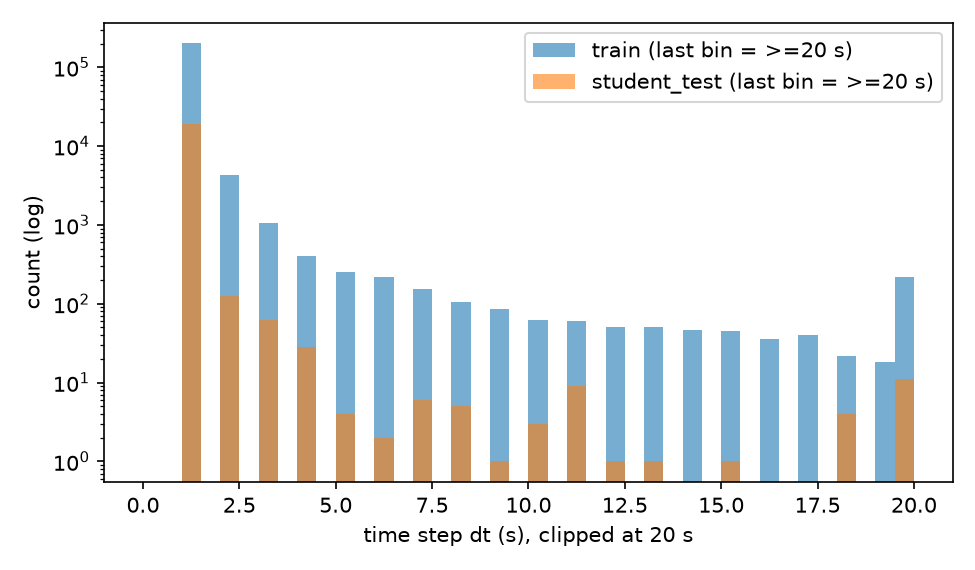

In [5]:
display(Image(str(OUT/'dt_hist.png')))

### 4. Geographic extent

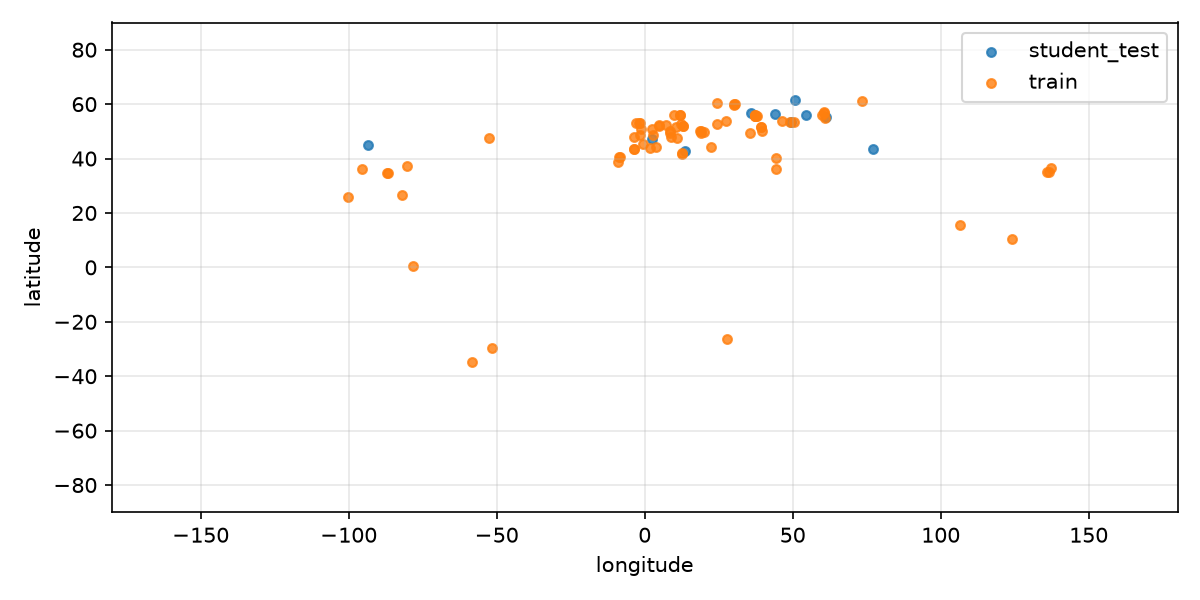

split            student_test      train
bbox_w_km count     10.000000  80.000000
          mean       9.926314  14.088049
          std       12.933392  16.264482
          min        2.189178   0.881010
          25%        3.205251   3.339941
          50%        5.285312   7.628222
          75%       10.386358  17.073705
          max       45.040813  70.920793
bbox_h_km count     10.000000  80.000000
          mean       9.137337  11.909127
          std        8.010773  14.647621
          min        1.807519   0.871972
          25%        3.804840   3.298833
          50%        5.914259   5.311194
          75%       11.644177  14.008837
          max       27.077393  75.081857

In [6]:
display(Image(str(OUT/'world_centroids.png')))
df.groupby('split')[['bbox_w_km','bbox_h_km']].describe().T

### 5. Road network

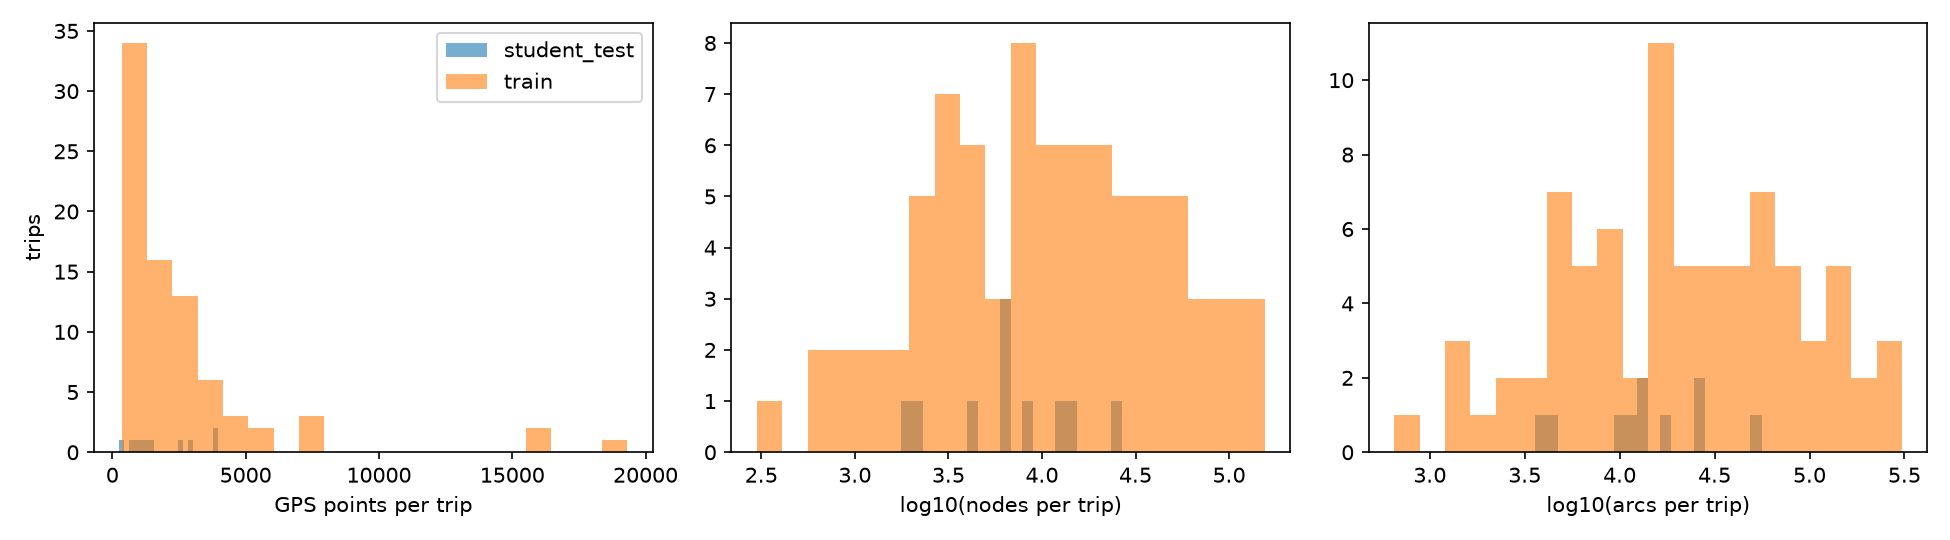

split                  student_test       train
weak_components count     10.000000   80.000000
                mean      22.700000   39.012500
                std       29.181615   60.682301
                min        5.000000    1.000000
                25%        7.250000    9.750000
...                             ...         ...
arc_len_p95_m   min       78.631879   55.324105
                25%       99.807285   99.780432
                50%      146.409772  121.670304
                75%      194.411207  171.098918
                max      297.538490  641.128168

[72 rows x 2 columns]

In [7]:
display(Image(str(OUT/'network_size.png')))
df.groupby('split')[['weak_components','strong_components','largest_weak_share','largest_strong_share','isolated_nodes','twin_ratio','zero_len_arcs','arc_len_median_m','arc_len_p95_m']].describe().T

### 6. Route analysis and GPS -> reference-route distance (exposes offset trips)

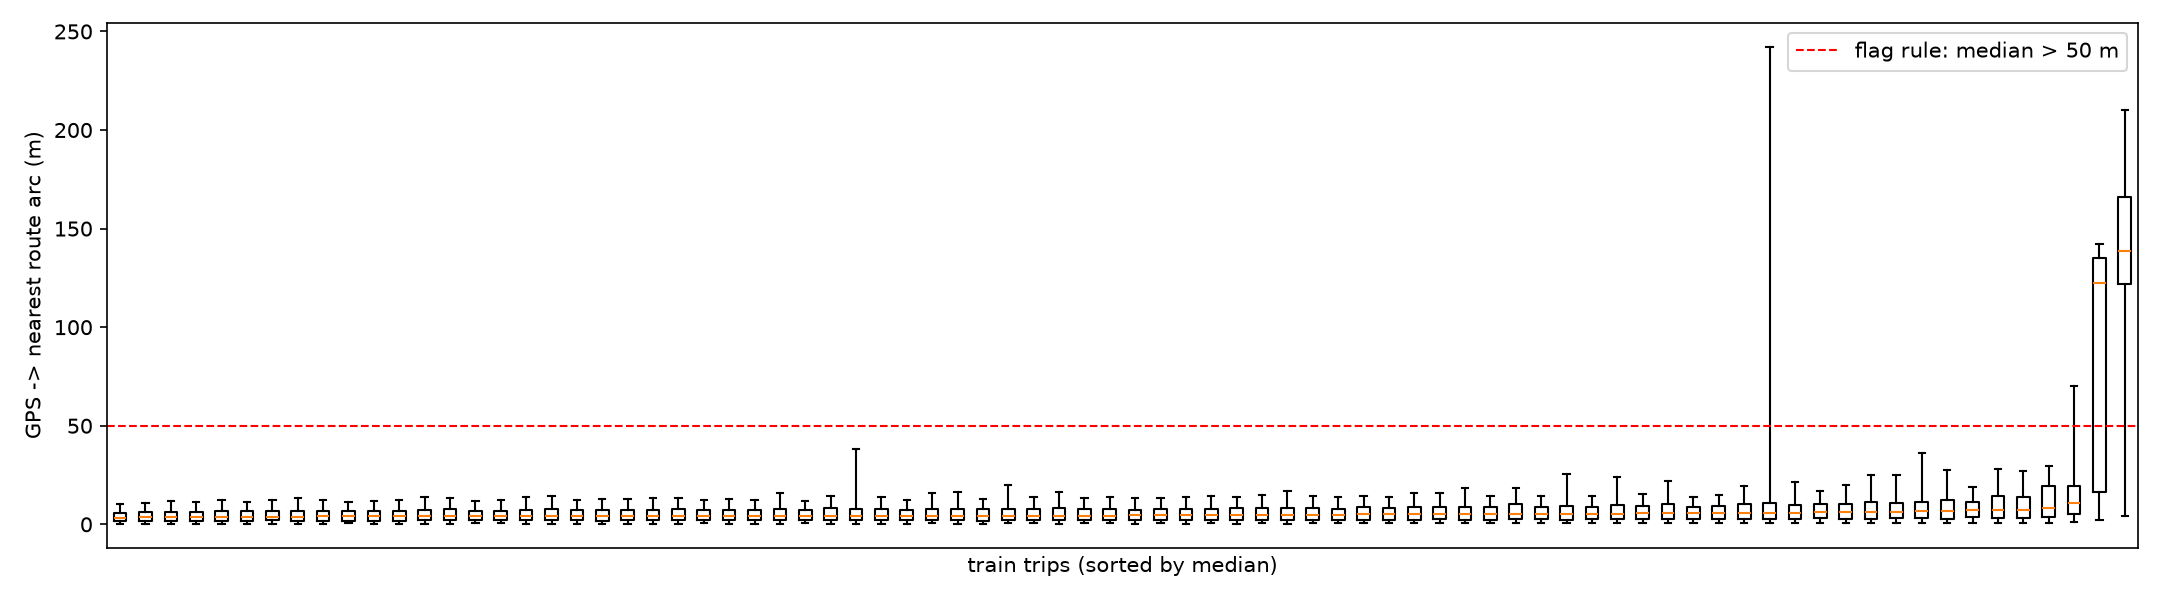

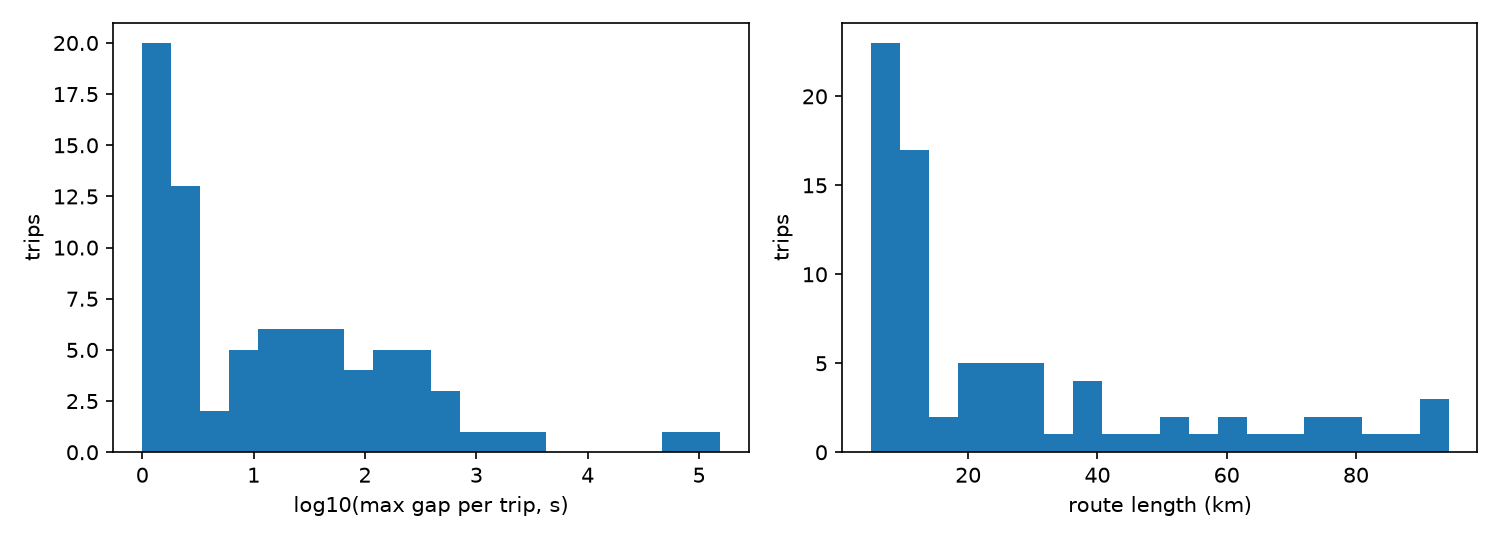

,count,mean,std,min,25%,50%,75%,max
route_arcs,80.0,391.700000,361.165497,59.000000,168.250000,280.000000,480.500000,2266.000000
route_km,80.0,27.856555,25.709461,5.014350,8.926649,14.313773,39.396756,94.338958
route_breaks,80.0,0.162500,0.488960,0.000000,0.000000,0.000000,0.000000,3.000000
route_repeated_arcs,80.0,0.837500,3.773471,0.000000,0.000000,0.000000,0.000000,29.000000
gps_route_dist_median_m,80.0,8.078808,19.803784,3.448296,4.232231,4.503265,5.472466,138.587916
gps_route_dist_p95_m,80.0,23.739964,36.517700,10.345466,12.985617,14.212412,18.537041,242.357309


In [8]:
display(Image(str(OUT/'gps_to_route_boxplot_train.png')))
display(Image(str(OUT/'gaps_and_route_length.png')))
df[df.split=='train'][['route_arcs','route_km','route_breaks','route_repeated_arcs','gps_route_dist_median_m','gps_route_dist_p95_m']].describe().T

**Offset / suspicious trips found by the rule** `median GPS->route distance > 50 m` (not hand-picked) - these are excluded from training labels (`label_valid=False`):

In [9]:
df.loc[df.flagged_offset == True, ['split','trip_id','gps_route_dist_median_m','gps_route_dist_p95_m','pct_gps_gt50m_from_route']]

,split,trip_id,gps_route_dist_median_m,gps_route_dist_p95_m,pct_gps_gt50m_from_route
26,train,00000033,122.413242,142.058649,58.949350
44,train,00000054,138.587916,210.050891,87.241754


## 7. Candidate generation: miss rate vs radius (train)
Miss rate = share of valid observations whose ground-truth arc is not among the candidates. Labels come from M3's alignment when `pathsnap.labels` exists, otherwise the documented fallback (see `label_source` column).

In [10]:
cs = E.candidate_stats(DATA_ROOT, OUT, 'train', flag_median_m=FLAG_MEDIAN_M, n_jobs=1)
cs

,split,radius_m,valid_obs,miss_rate_radius_only,miss_rate_radius_plus_knn,mean_cands_per_obs,k_min,k_max,label_source
0,train,20,178843,0.021483,0.00109,8.326768,8,30,M3_alignment
1,train,30,178843,0.000000,0.00005,9.012916,8,30,M3_alignment
2,train,50,178843,0.000000,0.00005,11.296770,8,30,M3_alignment
3,train,75,178843,0.000000,0.00005,14.361746,8,30,M3_alignment
4,train,100,178843,0.000000,0.00005,17.052304,8,30,M3_alignment


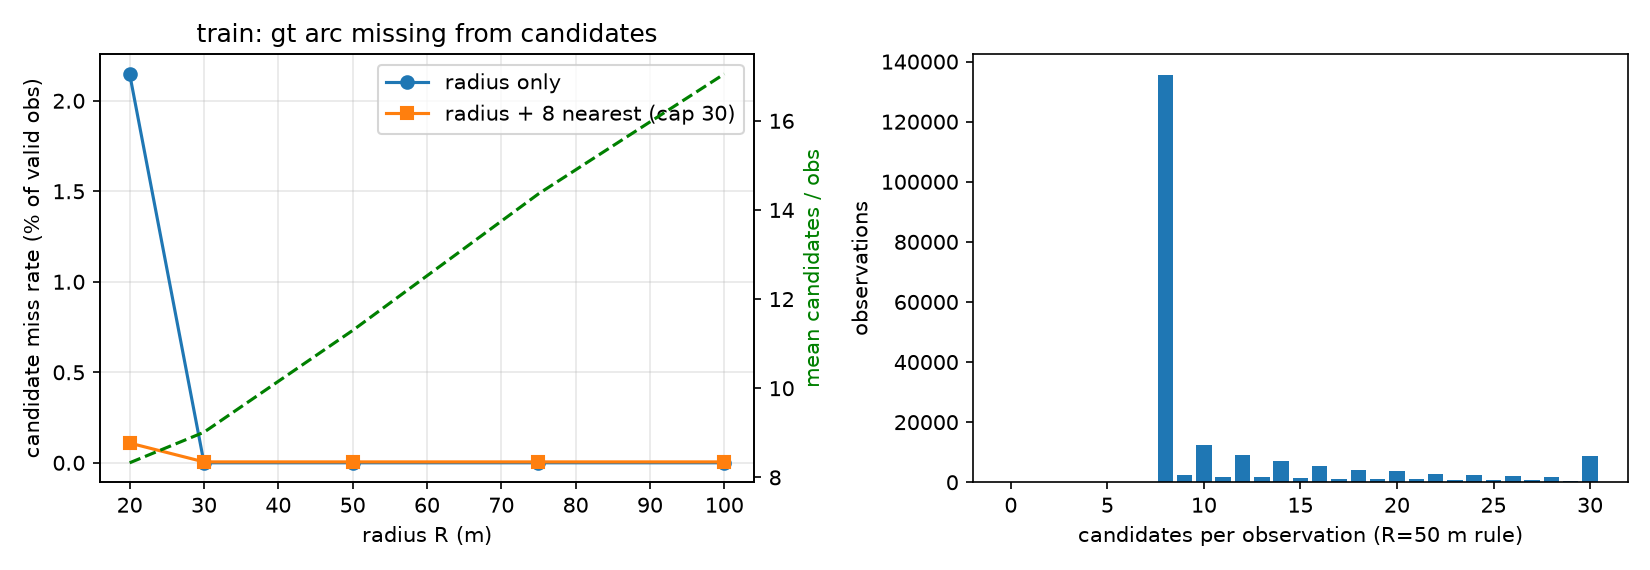

In [11]:
display(Image(str(OUT/'miss_rate_vs_radius.png')))

## 9. Data-quality issues, assumptions and decisions
*Fill from the tables above in your own words:*

| Issue | Evidence (from results/m1) | Decision |
|---|---|---|
| CRLF line endings | | whitespace-regex parsing |
| Sampling gaps (> 10 s) | | split into segments; windows/heading never cross a gap |
| Offset trips | | flagged by rule, `label_valid=False` |
| Route breaks / loops | | |
| Twin arcs (identical geometry) | | heading features |
| Worldwide extent | | per-trip UTM projection |